Dependencias

In [32]:
!pip install wget

In [3]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [34]:
pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 8.0 MB/s eta 0:00:008.7 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 8.3 MB/s eta 0:00:00m eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn]0m 5/6 [scikit-learn]]
Note: you may need to restart the kernel to use updated packages.


In [37]:
pip install seaborn matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 6.0 MB/s eta 0:00:000:00:010:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 7.0 MB/s eta 0:00:00 MB/s eta 0:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 6.6 MB/s eta 0:00:00 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 7.0 MB/s eta 0:00:00m eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [seaborn]━━━ 7/8 [seaborn]ib]
Note: you may need to restart the kernel to use updated packages.


In [35]:
import pandas as pd
import wget
from os import path, listdir
import numpy as np
from sklearn.preprocessing import MinMaxScaler

In [7]:
if not path.exists("schema.csv"):
  download("https://media.githubusercontent.com/media/StackExchange/Survey/refs/heads/main/packages/archive/2025/schema.csv")
if not path.exists("results.csv"):
  download("https://media.githubusercontent.com/media/StackExchange/Survey/6ae2209cd35a55e92739ba82f7887fb86807a069/packages/archive/2025/results.csv")
raw_dataset = pd.read_csv("results.csv",low_memory=False)
schema_dataset = pd.read_csv("schema.csv")

Hipotesis: Los desarrolladores que respondieron la encuesta de Argentina tienen
un salario 3 veces mayor al Salario Mínimo, Vital y Móvil (SMVM)

Vemos solo las columnas de tipo float para buscar las relacionadas al salario

In [8]:
raw_dataset.select_dtypes(include="float").columns

Index(['WorkExp', 'YearsCode', 'TechEndorse_1', 'TechEndorse_2',
       'TechEndorse_3', 'TechEndorse_4', 'TechEndorse_5', 'TechEndorse_6',
       'TechEndorse_7', 'TechEndorse_8', 'TechEndorse_9', 'TechEndorse_13',
       'TechOppose_1', 'TechOppose_2', 'TechOppose_3', 'TechOppose_5',
       'TechOppose_7', 'TechOppose_9', 'TechOppose_11', 'TechOppose_13',
       'TechOppose_16', 'TechOppose_15', 'JobSatPoints_1', 'JobSatPoints_2',
       'JobSatPoints_3', 'JobSatPoints_4', 'JobSatPoints_5', 'JobSatPoints_6',
       'JobSatPoints_7', 'JobSatPoints_8', 'JobSatPoints_9', 'JobSatPoints_10',
       'JobSatPoints_11', 'JobSatPoints_13', 'JobSatPoints_14',
       'JobSatPoints_15', 'JobSatPoints_16', 'ToolCountWork',
       'ToolCountPersonal', 'CompTotal', 'SO_Actions_1', 'SO_Actions_16',
       'SO_Actions_3', 'SO_Actions_4', 'SO_Actions_5', 'SO_Actions_6',
       'SO_Actions_9', 'SO_Actions_7', 'SO_Actions_10', 'SO_Actions_15',
       'ConvertedCompYearly', 'JobSat'],
      dtype='str')

Revisamos la columna salario de los encuestados que viven en argentina

In [23]:
salario = "ConvertedCompYearly"
encuestados_argentina = raw_dataset[raw_dataset["Country"]=="Argentina"]
encuestados_argentina[[salario]].info()

<class 'pandas.DataFrame'>
Index: 222 entries, 88 to 48790
Data columns (total 1 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ConvertedCompYearly  160 non-null    float64
dtypes: float64(1)
memory usage: 3.5 KB


Se puede observar que 160 de esos 222 registros son valores no nulos, eso quiere decir que 62 si lo son y corresponde a personas que no son asalariadas o decidieron no decir el valor de su salario

Limpiamos el dataset de los valores nulos

In [83]:
encuestados_argentina = encuestados_argentina.dropna(subset=[salario])
salario_encuestados_argentina=encuestados_argentina[salario]
salario_encuestados_argentina.info()

<class 'pandas.Series'>
Index: 160 entries, 88 to 48790
Series name: ConvertedCompYearly
Non-Null Count  Dtype  
--------------  -----  
160 non-null    float64
dtypes: float64(1)
memory usage: 2.5 KB


Buscamos cuanto es un Salario Minimo Vital y Movil en Argentina y cuanto es la cotizacion de la venta del dolar

In [76]:
import requests
respuesta = requests.get("https://api.argly.com.ar/v1/smvm")
datos = respuesta.json()
smvm = datos["data"]["smvm"]
print(f"Salario Minimo Vital y Movil en pesos: {smvm}")
respuesta_dolar = requests.get("https://dolarapi.com/v1/dolares/oficial")
precio_dolar = respuesta_dolar.json().get("venta")
print(f"Precio del dolar: {precio_dolar}")
smvm_dolarizado = smvm / precio_dolar
print(f"Salario Minimo Vital y Movil en dolares: {smvm_dolarizado}")

Salario Minimo Vital y Movil en pesos: 391200.0
Precio del dolar: 1545
Salario Minimo Vital y Movil en dolares: 253.20388349514562


Realizamos un boxplot y marcamos nuestro umbral de 3 SMVM

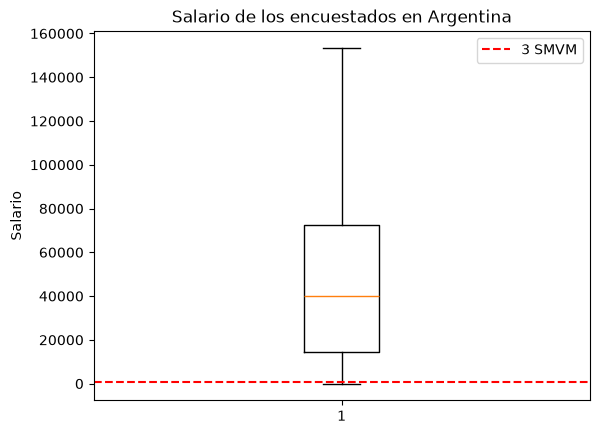

In [85]:
import matplotlib.pyplot as plt
umbral = 3 * smvm_dolarizado
plt.boxplot(salario_encuestados_argentina)
plt.axhline(y=umbral, color="red", linestyle="--", label="3 SMVM")
plt.title("Salario de los encuestados en Argentina")
plt.ylabel("Salario")
plt.legend()
plt.show()

Podemos ver que la gran mayoria (mucho mas del 75%) supera el umbral de 3 Salario Minimo Vital y Movil.
Ahora veamos cuanto es ese porcentaje especificamente

In [84]:
porcentaje_encima = (salario_encuestados_argentina > umbral).mean() * 100
print(f"Porcentaje de encuestados cuyo salario es mayor a 3 veces el Salario Minimo Vital y Movil: {porcentaje_encima}%")

Porcentaje de encuestados cuyo salario es mayor a 3 veces el Salario Minimo Vital y Movil: 91.25%
